# Longitudinal animal-progress analysis

Cross-session view of how an animal's *strategy* evolves in the Phase 3 cued task -
beyond a single accuracy number. Reads the per-session recordings via the
`tmaze.analysis` layer (all logic is tested there; this notebook is a thin
front-end) and shows:

1. Per-session **progression** (accuracy / bias, with a husbandry ribbon).
2. Rolling **strategy traces** (rolling accuracy, switch/alternation, win-stay,
   lose-shift, cue-follow, cue-switch->choice-switch), with intervention
   **blocks shaded**.
3. A rule-based **behavioural-mode decomposition** (disengaged / side-bias /
   alternating / lose-shift / win-stay / cue-following) + occupancy per session.
4. **Peri-intervention transitions**: does an *auto* block instigate a mode switch?
5. **Return-cue carryover**: does trial N-1's return cue bias the choice/switch at N?

Intervention blocks are kept as first-class labelled epochs (`free` / `in_block` /
`post_block`), never dropped. Notes/caveats:
- No per-excursion log exists for current recordings, so engagement uses an
  inter-trial-gap proxy and the `non-stem` mode reads "no data" until those logs ship.
- The return-cue term is partly endogenous (`return_cue_played` depends on the
  animal's own return path); the model controls for prior choice/reward but the
  result stays observational.

Run inside the `drieu_t_maze` env: `jupyter lab host/notebooks/animal_progress.ipynb`.

In [1]:
## 1. Configuration  -- edit these, then Run All
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tmaze.analysis import (
    bundle_reader,
    choice_signals,
    rolling_metrics,
    mode_label,
    intervention_response,
    progression,
    return_cue,
)

ANIMALS = ("600", "601", "602")   # which animals to load
START_DATE = "2026-08-28"                  # inclusive "YYYY-MM-DD" lower bound, or None
END_DATE = "2026-08-28"                    # inclusive "YYYY-MM-DD" upper bound, or None
WINDOW = 20                        # rolling window (completed trials)
POST_WINDOW = 10                   # NORMAL trials after a block that count as post-block
PRE_POST = 15                      # peri-intervention pre/post window (trials)
RECORDINGS_ROOT = None             # None -> paths.phase3_recordings_root() (TMAZE_RECORDINGS_DIR)
THRESHOLDS = mode_label.ModeThresholds()  # tune the mode cut-points here

ANIMAL = "602"                     # animal used for the single-animal detail plots
pd.set_option("display.width", 160)

In [2]:
## 2. Load sessions + shared helpers
data = bundle_reader.load_animals(ANIMALS, START_DATE, END_DATE, RECORDINGS_ROOT)
signals = choice_signals.add_signals(data.trials, post_window=POST_WINDOW)
HAS_EXC = rolling_metrics.has_excursion_data(data.excursions)
print(f"Loaded {len(data.sessions)} sessions, {len(signals)} trials; "
      f"per-excursion log present: {HAS_EXC}")


def animal_signals(animal):
    return signals[signals["animal"] == animal].copy()


# Per-session accuracy + left-choice bias over out-of-block trials (tested in
# tmaze.analysis.progression; same baseline set as the GUI - see ADR-0132).
summ = progression.per_session_summary(signals)
data.sessions[["session_id", "animal", "date", "generator", "n_trials",
               "stage", "pct_baseline", "hours_since_water"]]

Loaded 2 sessions, 294 trials; per-excursion log present: True


,session_id,animal,date,generator,n_trials,stage,pct_baseline,hours_since_water
0,600_20260828_142440,600,2026-08-28,intervention_blocks,182,Phase 3,1.0862,121.58
1,602_20260828_163536,602,2026-08-28,intervention_blocks,112,Phase 3,1.0609,123.76


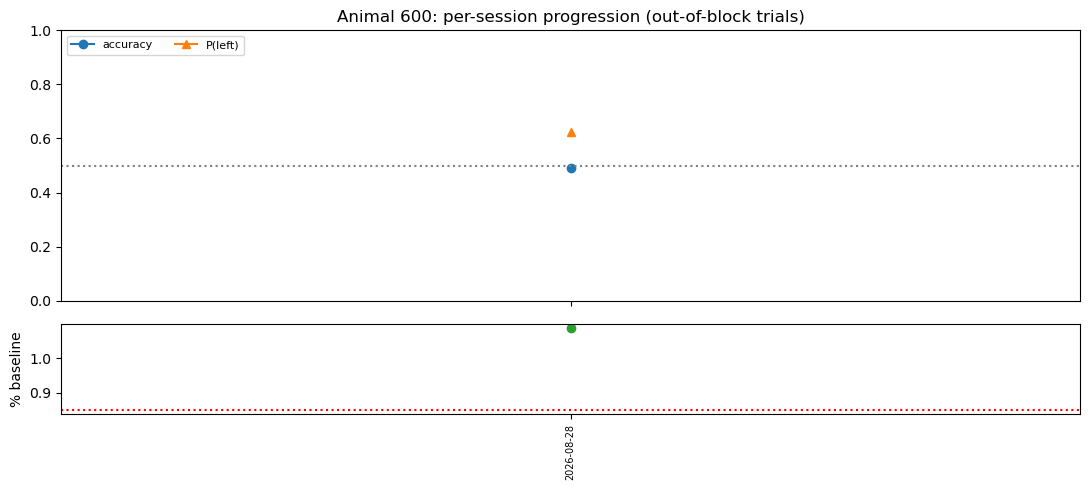

no data for 601


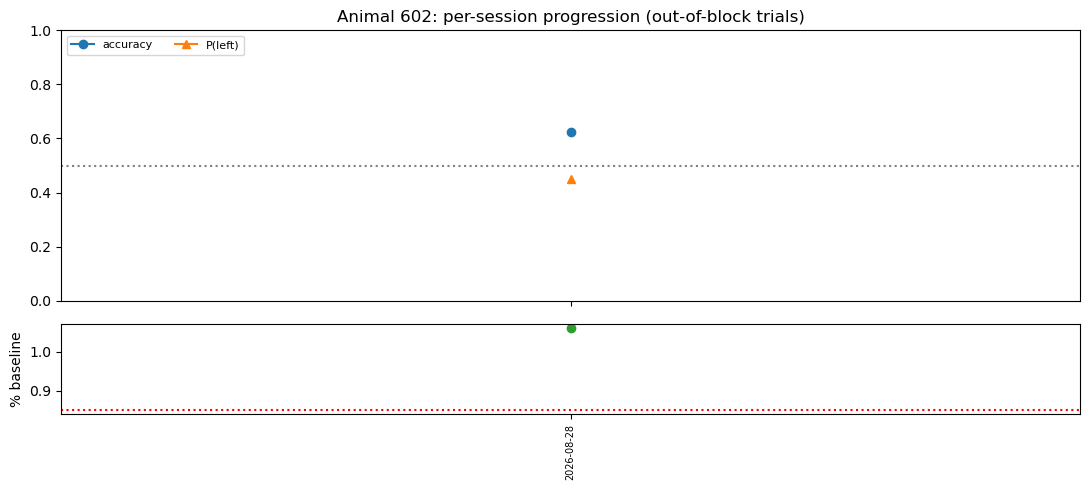

In [3]:
## 3. Per-session progression (all animals)
def plot_progression(animal):
    s = summ[summ["animal"] == animal].reset_index(drop=True)
    if s.empty:
        print("no data for", animal)
        return
    fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True,
                           gridspec_kw={"height_ratios": [3, 1]})
    x = range(len(s))
    ax[0].plot(x, s["accuracy"], "-o", label="accuracy")
    ax[0].plot(x, s["side_bias_left"], "-^", label="P(left)")
    ax[0].axhline(0.5, ls=":", c="gray")
    ax[0].set_ylim(0, 1)
    ax[0].legend(loc="upper left", ncol=2, fontsize=8)
    ax[0].set_title(f"Animal {animal}: per-session progression (out-of-block trials)")

    ses = data.sessions[data.sessions["animal"] == animal].set_index("session_id")
    pct = [ses["pct_baseline"].get(sid, np.nan) for sid in s["session_id"]]
    ax[1].plot(x, pct, "-o", color="tab:green")
    ax[1].set_ylabel("% baseline")
    ax[1].axhline(0.85, ls=":", c="red")
    ax[1].set_xticks(list(x))
    ax[1].set_xticklabels(s["date"], rotation=90, fontsize=7)
    plt.tight_layout()
    plt.show()


for a in ANIMALS:
    plot_progression(a)

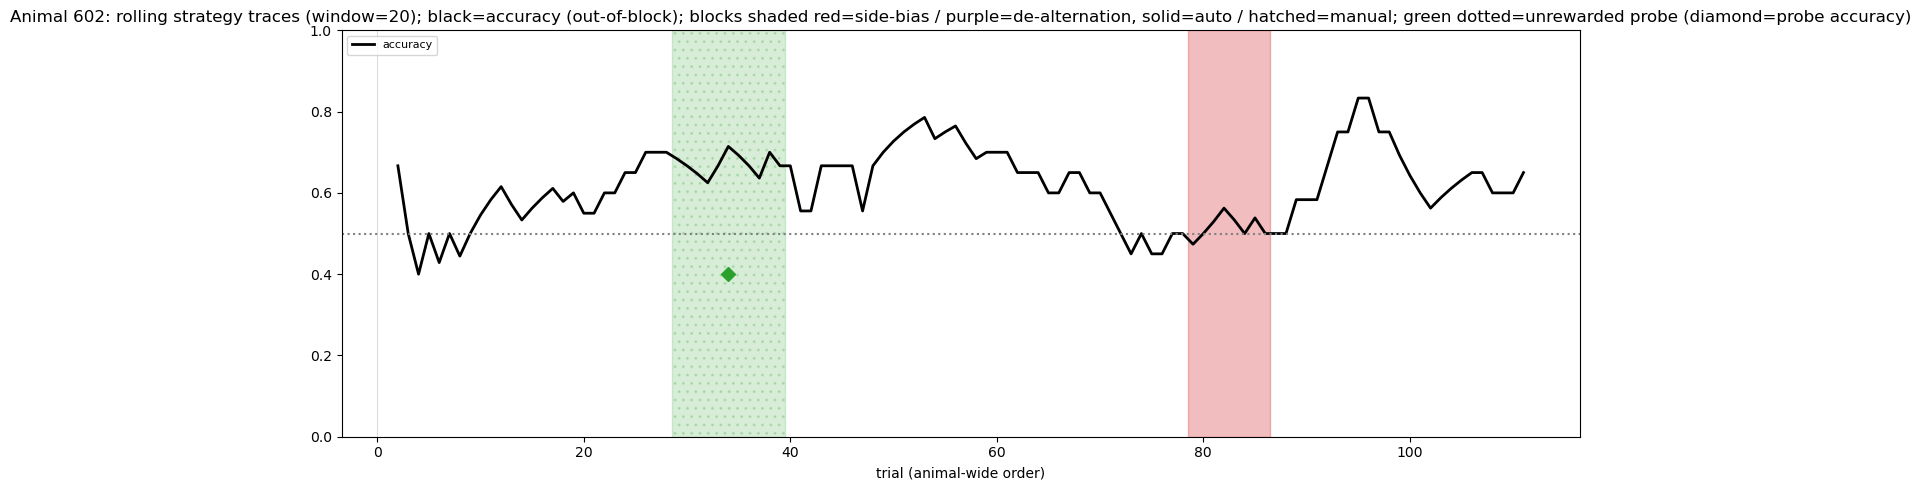

In [4]:
## 4. Rolling strategy traces (blocks shaded)  -- ANIMAL
_KIND_COLOR = {"side_bias": "tab:red", "alternation": "tab:purple"}


def plot_traces(animal, window=WINDOW, show_cue_acc=False):
    sig = animal_signals(animal)
    res = rolling_metrics.build_traces(sig, window=window)
    tr = res.traces
    if tr.empty:
        print("no data for", animal)
        return res
    fig, ax = plt.subplots(figsize=(13, 5))
    # Rolling accuracy (out-of-block) drawn heavier so it reads as the headline
    # line, mirroring the live GUI Metrics tab. Set show_cue_acc=True for the
    # cue-conditioned high/low accuracy split (off by default to avoid clutter).
    ax.plot(tr["seq"], tr["accuracy"], label="accuracy", lw=2.0, color="black")
    if show_cue_acc:
        ax.plot(tr["seq"], tr["high_acc"], label="accuracy | HIGH cue", lw=1.0,
                ls="--", color="black", alpha=0.6)
        ax.plot(tr["seq"], tr["low_acc"], label="accuracy | LOW cue", lw=1.0,
                ls=":", color="black", alpha=0.6)
    #for col, lab in [("switch_rate", "switch/alternation"),
    #                 ("win_stay", "win-stay"), ("lose_shift", "lose-shift"),
    #                 ("cue_follow", "cue-follow"),
    #                 ("cue_switch_tracks", "cue-switch->choice-switch"),
    #                 ("side_bias_left", "P(left)")]:
    #    ax.plot(tr["seq"], tr[col], label=lab, lw=1.2)
    for b in res.blocks:
        color = _KIND_COLOR.get(b["kind"], "gray")
        ax.axvspan(b["start_seq"] - 0.5, b["end_seq"] + 0.5, color=color,
                   alpha=0.30 if b["trigger"] == "auto" else 0.12,
                   hatch=None if b["trigger"] == "auto" else "//")
    # Unrewarded probe blocks: teal shading + per-block latent-knowledge accuracy.
    for p in res.probe_blocks:
        ax.axvspan(p["start_seq"] - 0.5, p["end_seq"] + 0.5, color="tab:green",
                   alpha=0.18, hatch="..")
        if p["accuracy"] is not None:
            mid = 0.5 * (p["start_seq"] + p["end_seq"])
            ax.plot([mid], [p["accuracy"]], "D", color="tab:green", ms=7,
                    zorder=5)
    for sb in res.session_bounds:
        ax.axvline(sb["start_seq"], color="lightgray", lw=0.6)
    ax.set_ylim(0, 1)
    ax.axhline(0.5, ls=":", c="gray")
    ax.set_xlabel("trial (animal-wide order)")
    ax.set_ylabel("")
    ax.set_title(f"Animal {animal}: rolling strategy traces (window={window}); "
                 "black=accuracy (out-of-block); blocks shaded red=side-bias / "
                 "purple=de-alternation, solid=auto / hatched=manual; "
                 "green dotted=unrewarded probe (diamond=probe accuracy)")
    ax.legend(ncol=3, fontsize=8, loc="upper left")
    plt.tight_layout()
    plt.show()
    return res


res_animal = plot_traces(ANIMAL)

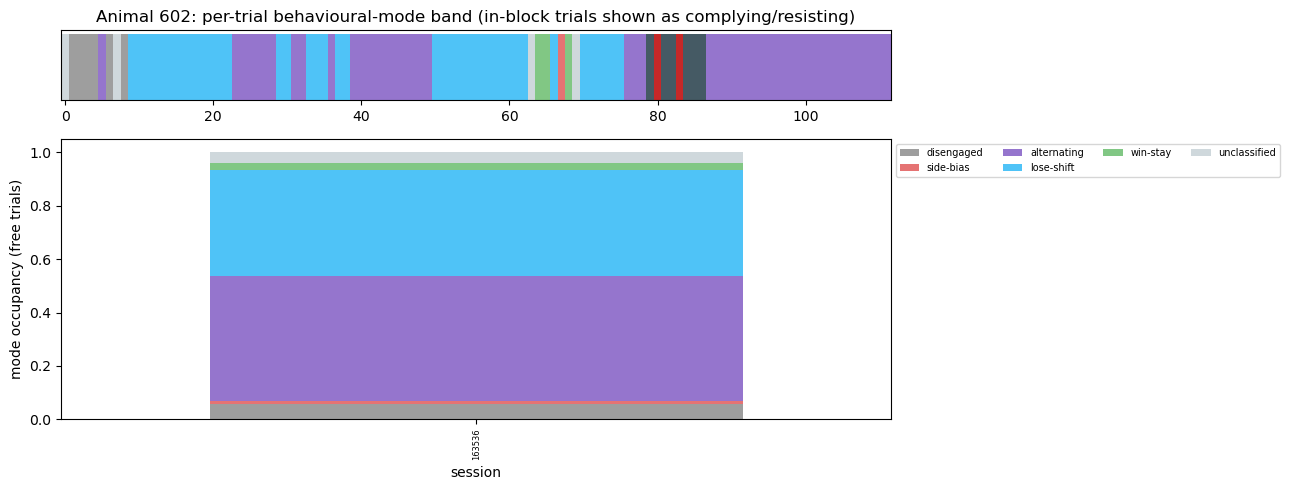

In [5]:
## 5. Behavioural-mode decomposition  -- ANIMAL
MODE_COLORS = {
    "disengaged": "#9e9e9e", "non-stem": "#8d6e63", "side-bias": "#e57373",
    "alternating": "#9575cd", "lose-shift": "#4fc3f7", "win-stay": "#81c784",
    "cue-following": "#ffb300", "unclassified": "#cfd8dc",
    "complying": "#455a64", "resisting": "#c62828",
}


def plot_mode_band(animal, res):
    tr = res.traces
    if tr.empty:
        print("no data for", animal)
        return None
    lab = mode_label.label_modes(tr, THRESHOLDS, has_excursions=HAS_EXC)
    fig, ax = plt.subplots(2, 1, figsize=(13, 5),
                           gridspec_kw={"height_ratios": [1, 4]})
    seq = lab["seq"].to_numpy()
    colors = [MODE_COLORS.get(m, "#000000") for m in lab["mode"]]
    ax[0].bar(seq, np.ones(len(seq)), width=1.0, color=colors, linewidth=0)
    ax[0].set_yticks([])
    ax[0].set_xlim(seq.min() - 0.5, seq.max() + 0.5)
    ax[0].set_title(f"Animal {animal}: per-trial behavioural-mode band "
                    "(in-block trials shown as complying/resisting)")
    occ = mode_label.mode_occupancy(lab)
    if not occ.empty:
        occ.plot(kind="bar", stacked=True, ax=ax[1], width=0.9,
                 color=[MODE_COLORS.get(c, "#000000") for c in occ.columns])
        ax[1].set_ylabel("mode occupancy (free trials)")
        ax[1].set_xlabel("session")
        ax[1].set_xticklabels([s[-6:] for s in occ.index], rotation=90, fontsize=6)
        ax[1].legend(ncol=4, fontsize=7, bbox_to_anchor=(1.0, 1.0))
    plt.tight_layout()
    plt.show()
    return lab


lab_animal = plot_mode_band(ANIMAL, res_animal)

Animal 602: 1 auto-block transitions; 100% changed dominant mode


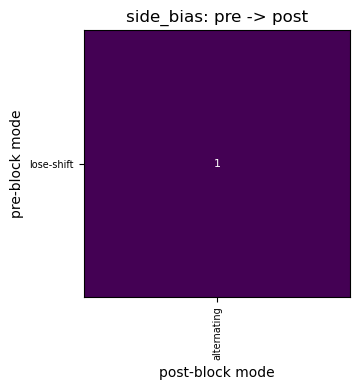

In [6]:
## 6. Peri-intervention transitions (AUTO blocks only)  -- ANIMAL
def plot_peri(animal, res, lab):
    if lab is None or not res.blocks:
        print("no blocks for", animal)
        return None
    pt = intervention_response.peri_transitions(
        lab, res.blocks, pre_window=PRE_POST, post_window=PRE_POST)
    if pt.empty:
        print("no auto-block transitions for", animal)
        return pt
    print(f"Animal {animal}: {len(pt)} auto-block transitions; "
          f"{pt['changed'].mean() * 100:.0f}% changed dominant mode")
    kinds = list(pt["kind"].unique())
    fig, axes = plt.subplots(1, len(kinds), figsize=(5 * len(kinds), 4),
                             squeeze=False)
    for ax, k in zip(axes[0], kinds):
        m = intervention_response.transition_matrix(pt, kind=k)
        ax.imshow(m.values, cmap="viridis")
        ax.set_xticks(range(len(m.columns)))
        ax.set_xticklabels(m.columns, rotation=90, fontsize=7)
        ax.set_yticks(range(len(m.index)))
        ax.set_yticklabels(m.index, fontsize=7)
        ax.set_title(f"{k}: pre -> post")
        ax.set_xlabel("post-block mode")
        ax.set_ylabel("pre-block mode")
        for (i, j), v in np.ndenumerate(m.values):
            ax.text(j, i, int(v), ha="center", va="center",
                    color="w", fontsize=8)
    plt.tight_layout()
    plt.show()
    return pt

    
pt_animal = plot_peri(ANIMAL, res_animal, lab_animal)

In [7]:
## 7. Return-cue carryover: does N-1's return cue bias choice/switch at N?
# Aggregation + Wilson confidence intervals live in tmaze.analysis.return_cue
# (tested); this cell only plots. The return cue is partly endogenous (which cue
# plays depends on the animal's own return path), so this stays observational.
_CONG_COLOR = {True: "tab:green", False: "tab:red"}


def return_cue_panel(animal):
    summ = return_cue.return_cue_switch_summary(animal_signals(animal))
    if summ.switch.empty:
        print("no usable pairs for", animal)
        return
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))

    labels, ps, lo_err, hi_err, colors = [], [], [], [], []
    for cong in (True, False):
        row = summ.switch[summ.switch["congruent"] == cong]
        if row.empty:
            continue
        row = row.iloc[0]
        labels.append(f"{'congruent' if cong else 'incongruent'}\n(n={int(row['n'])})")
        ps.append(row["p"])
        lo_err.append(row["p"] - row["lo"])
        hi_err.append(row["hi"] - row["p"])
        colors.append(_CONG_COLOR[cong])
    ax[0].bar(labels, ps, yerr=[lo_err, hi_err], capsize=5, color=colors)
    ax[0].axhline(0.5, ls=":", c="gray")
    ax[0].set_ylim(0, 1)
    ax[0].set_ylabel("P(switch at N)")
    ax[0].set_title(f"Animal {animal}: N-1 return-cue congruency -> switch at N")

    ax[1].bar(["P(choice = N-1 return-cue side)"], [summ.match_p],
              yerr=[[summ.match_p - summ.match_lo], [summ.match_hi - summ.match_p]],
              capsize=5, color="tab:blue")
    ax[1].axhline(0.5, ls=":", c="gray")
    ax[1].set_ylim(0, 1)
    ax[1].set_title(f"n={summ.match_n} (observational; return cue is partly endogenous)")
    plt.tight_layout()
    plt.show()


for a in ANIMALS:
    return_cue_panel(a)

no usable pairs for 600
no usable pairs for 601
no usable pairs for 602
